# S2 — profile: NER entity occurrences, chronam
Read-only profile of `data/raw/ner_chronam/part-00000.parquet` (one row = one entity mention in one OCR block). Task: `tasks/T-001-s2-profile-news.md`. Caveats: `docs/DATA.md`.
Method: DuckDB SQL; nothing written to `data/`. The NER labels were produced upstream by Revolution Crossroads; **this notebook runs no model**. Entity strings are not resolved people.
Source: `RevX_NER_Entity_Occurrences`, revision `54b6ea35…` (see `data/raw/MANIFEST.md`).

In [1]:
import duckdb, pandas as pd
from pathlib import Path
pd.set_option('display.width',200); pd.set_option('display.max_rows',80); pd.set_option('display.max_colwidth',100)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data'/'raw').exists())
NER=str(ROOT/'data/raw/ner_chronam/part-00000.parquet'); NEWS=str(ROOT/'data/raw/news/*.parquet')
con=duckdb.connect()
con.sql(f"""create view ner as select *,
  regexp_extract(record_id,'^([^_]+)_(\\d{{4}}-\\d{{2}}-\\d{{2}})_(\\d+)$',1) lccn,
  try_cast(regexp_extract(record_id,'^([^_]+)_(\\d{{4}}-\\d{{2}}-\\d{{2}})_(\\d+)$',2) as date) issue_date,
  try_cast(regexp_extract(record_id,'^([^_]+)_(\\d{{4}}-\\d{{2}}-\\d{{2}})_(\\d+)$',3) as int) edition_order
  from read_parquet('{NER}')""")
con.sql(f"create view news as select lccn,issue_date::date issue_date,edition_order,Page,newspaper_title from read_parquet('{NEWS}')")
q=lambda s: con.sql(s).df()
q("select count(*) rows, count(distinct record_id) record_ids, count(distinct (record_id,page,block_id)) blocks, count(distinct entity_text_normalised) distinct_entities from ner")

,rows,record_ids,blocks,distinct_entities
0,12318433,19431,3170418,1007299


## 1. Rows, nulls, record_id format

In [2]:
cols=['record_id','page','block_id','entity_type','entity_text_normalised','block_text','block_bbox']
q("select "+",".join(f"sum(({c} is null)::int) {c}" for c in cols)+" from ner").T.rename(columns={0:'null'})

,null
record_id,0.0
page,0.0
block_id,0.0
entity_type,0.0
entity_text_normalised,0.0
block_text,0.0
block_bbox,0.0


In [3]:
q("select sum((lccn='' or issue_date is null or edition_order is null)::int) unparsable_record_ids, count(*) n from ner"), q("select record_id from ner where lccn='' or issue_date is null limit 5")

(   unparsable_record_ids         n
 0                    0.0  12318433,
 Empty DataFrame
 Columns: [record_id]
 Index: [])

## 2. Dates by year (parsed from `record_id`)

,yr,mentions,issues,blocks
0,1770,53800,113,13543
1,1771,73104,136,18013
2,1772,93386,171,23688
3,1773,119919,209,30841
4,1774,178586,284,42061
5,1775,189611,294,46047
6,1776,263349,537,65964
7,1777,154162,315,42465
8,1778,118197,249,30992
9,1779,220615,415,55722


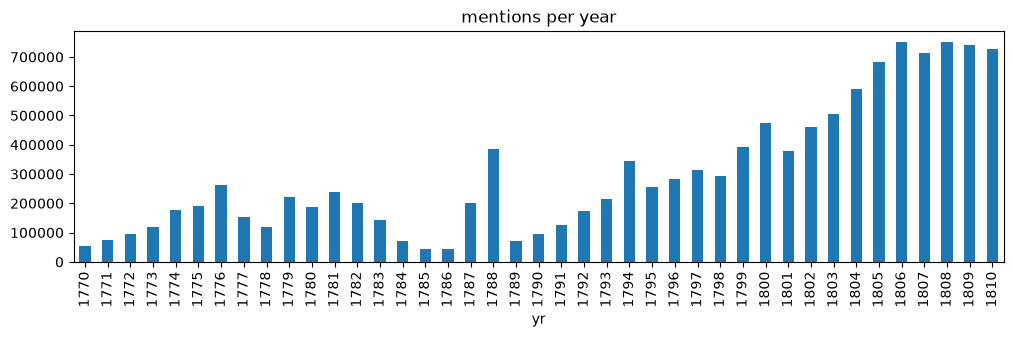

In [4]:
yr=q("select year(issue_date) yr, count(*) mentions, count(distinct record_id) issues, count(distinct (record_id,page,block_id)) blocks from ner group by 1 order by 1"); display(yr)
yr.set_index('yr')['mentions'].plot(kind='bar',figsize=(12,3),title='mentions per year');

## 3. `entity_type` counts

In [5]:
et=q("select entity_type, count(*) n, round(100*count(*)/sum(count(*)) over(),2) pct, count(distinct entity_text_normalised) distinct_strings from ner group by 1 order by n desc"); et

,entity_type,n,pct,distinct_strings
0,geographic_location,3863903,31.37,80784
1,person,3833286,31.12,498475
2,temporal_event,1251948,10.16,75912
3,named_place,1176421,9.55,143866
4,organization,886628,7.20,86757
5,calendar_date,568090,4.61,111327
6,named_vessel,463717,3.76,54108
7,norp,231007,1.88,6536
8,named_event,43433,0.35,7700


## 4. Top places (`geographic_location` + `named_place`)
The task said GPE/LOC; the actual `entity_type` vocabulary has no GPE or LOC (see section 3), so the two place-like labels are used.

In [6]:
print(et.entity_type.tolist())
PLACE_TYPES=[t for t in et.entity_type if t in ('geographic_location','named_place')]; print('using',PLACE_TYPES)
pt=",".join(f"'{t}'" for t in PLACE_TYPES)
q(f"select entity_type, entity_text_normalised place, count(*) n, count(distinct record_id) issues from ner where entity_type in ({pt}) group by 1,2 order by n desc limit 40")

['geographic_location', 'person', 'temporal_event', 'named_place', 'organization', 'calendar_date', 'named_vessel', 'norp', 'named_event']
using ['geographic_location', 'named_place']


,entity_type,place,n,issues
0,geographic_location,philadelphia,126579,17871
1,geographic_location,united states,120978,15980
2,geographic_location,france,105826,16435
3,geographic_location,new-york,93759,15548
4,geographic_location,london,80052,16960
5,geographic_location,america,67209,13768
6,geographic_location,boston,66181,14927
7,geographic_location,england,63550,15842
8,geographic_location,virginia,57358,15159
9,geographic_location,portsmouth,56593,8833


In [7]:
# place strings merged across GPE/LOC; most strings are OCR noise in the long tail
q(f"select entity_text_normalised place, count(*) n from ner where entity_type in ({pt}) group by 1 order by n desc limit 40").T if False else q(f"select count(distinct entity_text_normalised) distinct_place_strings, sum((c=1)::int) seen_once from (select entity_text_normalised, count(*) c from ner where entity_type in ({pt}) group by 1)")

,distinct_place_strings,seen_once
0,209761,120390.0


In [8]:
# frontier / western place strings (exact normalised matches)
W=['ohio','kentucky','tennessee','indiana','illinois','mississippi','louisiana','natchez','detroit','vincennes','pittsburgh','marietta','cincinnati','louisville','lexington','new orleans','northwest territory','western territory','genesee','georgia']
q(f"select entity_text_normalised place, entity_type, count(*) n from ner where entity_type in ({pt}) and entity_text_normalised in ({','.join(repr(w) for w in W)}) group by 1,2 order by n desc")

,place,entity_type,n
0,lexington,geographic_location,32261
1,kentucky,geographic_location,18202
2,georgia,geographic_location,15869
3,ohio,geographic_location,10323
4,louisiana,geographic_location,9863
5,new orleans,geographic_location,8528
6,tennessee,geographic_location,6053
7,mississippi,named_place,5310
8,pittsburgh,geographic_location,3259
9,natchez,geographic_location,3080


## 5. How NER `record_id` joins news (`lccn` + date + edition)

In [9]:
con.sql("create or replace table ner_keys as select distinct lccn, issue_date, edition_order from ner")
con.sql("create or replace table news_keys as select lccn, issue_date, edition_order, count(*) pages from news group by 1,2,3")
q("""select (select count(*) from ner_keys) ner_issues, (select count(*) from news_keys) news_issues,
 (select count(*) from ner_keys n join news_keys w using(lccn,issue_date,edition_order)) joined_3key,
 (select count(*) from ner_keys n join news_keys w using(lccn,issue_date)) joined_lccn_date""")

,ner_issues,news_issues,joined_3key,joined_lccn_date
0,19431,19445,19431,19709


In [10]:
# unmatched on either side
print('NER issues with no news match:'); display(q("select n.* from ner_keys n anti join news_keys w using(lccn,issue_date,edition_order) limit 10"))
print('news issues with no NER:'); display(q("select w.lccn,w.issue_date,w.edition_order,w.pages from news_keys w anti join ner_keys n using(lccn,issue_date,edition_order) limit 10"))
q("""select year(w.issue_date) yr, count(*) news_issues, sum((n.lccn is not null)::int) with_ner, round(100*avg((n.lccn is not null)::int),1) pct from news_keys w left join ner_keys n using(lccn,issue_date,edition_order) group by 1 order by 1""")

NER issues with no news match:


,lccn,issue_date,edition_order


news issues with no NER:


,lccn,issue_date,edition_order,pages
0,sn82016139,1778-01-20,1,4
1,sn85025815,1807-03-16,1,4
2,sn83025790,1783-05-24,1,4
3,sn82014782,1793-01-12,2,4
4,sn82014782,1793-01-19,2,4
5,sn82014782,1793-01-26,2,4
6,sn83016063,1800-04-21,1,2
7,sn82014782,1793-01-12,1,4
8,sn82014782,1793-01-19,1,4
9,sn82014782,1793-01-26,1,4


,yr,news_issues,with_ner,pct
0,1770,113,113.0,100.0
1,1771,136,136.0,100.0
2,1772,171,171.0,100.0
3,1773,209,209.0,100.0
4,1774,284,284.0,100.0
5,1775,294,294.0,100.0
6,1776,537,537.0,100.0
7,1777,315,315.0,100.0
8,1778,250,249.0,99.6
9,1779,415,415.0,100.0


In [11]:
# does the NER 'page' column line up with news Page? (news rows per issue vs NER distinct pages per issue)
q("""with a as (select lccn,issue_date,edition_order, count(distinct page) ner_pages, min(page) pmin, max(page) pmax from ner group by 1,2,3)
select count(*) joined, sum((ner_pages<=pages)::int) ner_pages_le_news, sum((pmax<=pages)::int) maxpage_within_news, min(pmin) min_ner_page, max(pmax) max_ner_page
from a join news_keys using(lccn,issue_date,edition_order)""")

,joined,ner_pages_le_news,maxpage_within_news,min_ner_page,max_ner_page
0,19431,19431.0,19431.0,1,16


In [12]:
q("select min(page) mn, max(page) mx, sum((page=0)::int) zero_based from ner"), q("select min(Page) mn, max(Page) mx from news")

(   mn  mx  zero_based
 0   1  16         0.0,
    mn  mx
 0   1  17)

## 6. Block text, blocks per page, block_id types

In [13]:
q("select regexp_extract(block_id,'^/page/\\d+/([A-Za-z]+)/',1) block_type, count(distinct (record_id,page,block_id)) blocks, count(*) mentions from ner group by 1 order by blocks desc")

,block_type,blocks,mentions
0,Text,2880867,11482706
1,SectionHeader,251746,342477
2,Table,18281,248996
3,ListGroup,17124,232109
4,ComplexRegion,1408,9273
5,Footnote,863,2415
6,Caption,103,159
7,TableOfContents,15,261
8,Form,8,34
9,Picture,3,3


In [14]:
q("select count(*) n, min(length(block_text)) mn, median(length(block_text)) med, quantile_cont(length(block_text),.95) p95, max(length(block_text)) mx from ner")

,n,mn,med,p95,mx
0,12318433,1,410.0,2278.0,36367


In [15]:
# is the entity string actually in the block text? (normalisation check)
q("select round(100*avg(contains(lower(block_text), entity_text_normalised)::int),1) pct_entity_found_in_block_lower from (select * from ner using sample 200000 rows)")

,pct_entity_found_in_block_lower
0,100.0


## 7. Blocks with Native terms, by year
Same two term lists as the news notebook (prototype 2 `native` regex = narrow; broad generic list for comparison). Regex on `block_text`, counted per distinct block (not per mention).

,yr,blocks,proto_blocks,protowb_blocks,broad_blocks,strict_blocks,proto_pct,protowb_pct,broad_pct,strict_pct
0,1770,13543,67.0,0.0,172.0,73.0,0.49,0.00,1.27,0.54
1,1771,18013,75.0,7.0,342.0,147.0,0.42,0.04,1.90,0.82
2,1772,23688,85.0,9.0,539.0,189.0,0.36,0.04,2.28,0.80
3,1773,30841,96.0,10.0,689.0,269.0,0.31,0.03,2.23,0.87
4,1774,42061,204.0,16.0,1257.0,571.0,0.49,0.04,2.99,1.36
5,1775,46047,168.0,23.0,1174.0,707.0,0.36,0.05,2.55,1.54
6,1776,65964,212.0,10.0,2054.0,922.0,0.32,0.02,3.11,1.40
7,1777,42465,59.0,6.0,1316.0,444.0,0.14,0.01,3.10,1.05
8,1778,30992,108.0,5.0,809.0,333.0,0.35,0.02,2.61,1.07
9,1779,55722,126.0,3.0,1768.0,724.0,0.23,0.01,3.17,1.30


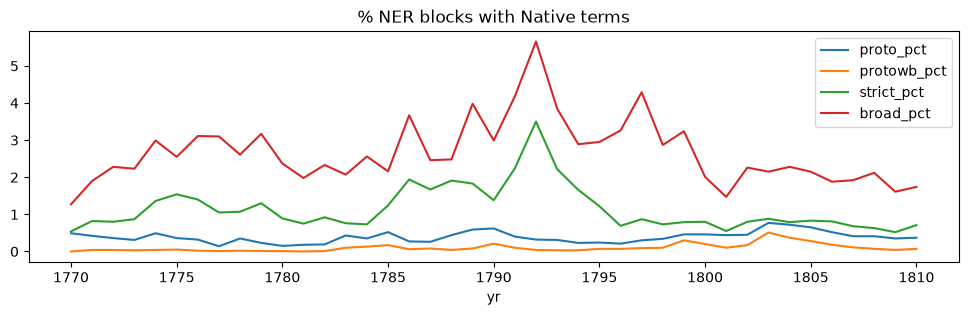

In [16]:
NATIVE_PROTO=r"indian (?:title|claim|lands?|boundary|purchase|treaty)|lands? (?:lately )?ceded|purchased of the indians|treaty of greenville|cession"
NATIVE_PROTO_WB=NATIVE_PROTO.replace("|cession",r"|\bcession\b")  # prototype list with a word boundary: plain "cession" also matches concession/succession
NATIVE_BROAD=r"\bindians?\b|\bcherokees?\b|\bchickasaws?\b|\bchoctaws?\b|\bcreeks?\b|\bshawan(?:ese|oes)\b|\bshawnees?\b|\bdelawares?\b|\bmiamis?\b|\biroquois\b|\bsix nations\b|\bseneca\b|\bmohawks?\b|\bwyandots?\b|\bpotawatom(?:ies|i)\b|\bmuskingum\b"
NATIVE_STRICT=r"\bindians?\b|\bcherokees?\b|\bchickasaws?\b|\bchoctaws?\b|\bshawan(?:ese|oes)\b|\bshawnees?\b|\biroquois\b|\bsix nations\b|\bmohawks?\b|\bwyandots?\b|\bpotawatom(?:ies|i)\b"  # broad minus delaware/creek/miami/seneca/muskingum (place or surname collisions)
con.execute(f"""create or replace table blocks as select record_id, page, block_id, year(any_value(issue_date)) yr, any_value(lower(block_text)) t, count(*) mentions from ner group by 1,2,3""")
b=q(f"""select yr, count(*) blocks, sum(regexp_matches(t,'{NATIVE_PROTO}')::int) proto_blocks, sum(regexp_matches(t,'{NATIVE_PROTO_WB}')::int) protowb_blocks, sum(regexp_matches(t,'{NATIVE_BROAD}')::int) broad_blocks, sum(regexp_matches(t,'{NATIVE_STRICT}')::int) strict_blocks from blocks group by 1 order by 1""")
b['proto_pct']=(100*b.proto_blocks/b.blocks).round(2); b['protowb_pct']=(100*b.protowb_blocks/b.blocks).round(2); b['broad_pct']=(100*b.broad_blocks/b.blocks).round(2); b['strict_pct']=(100*b.strict_blocks/b.blocks).round(2)
display(b); b.set_index('yr')[['proto_pct','protowb_pct','strict_pct','broad_pct']].plot(figsize=(12,3),title='% NER blocks with Native terms');

In [17]:
# NB: only blocks that contain >=1 entity exist in this table; blocks without entities are absent
print('total blocks in NER table:', len(q('select 1 from blocks')))
q(f"""select yr, regexp_extract(t,'((?s).{{0,70}}(?:{NATIVE_PROTO}).{{0,70}})',1) snippet from (select * from blocks where regexp_matches(t,'{NATIVE_PROTO}') order by hash(record_id||block_id) limit 8)""")

total blocks in NER table: 3170418


,yr,snippet
0,1806,tration of the national honor at the feet of our adversary: that a concession so humiliating wou...
1,1788,d several workmen concerned in this beautiful feature in our grand procession. these particulars...
2,1808,"ome into an english port and paid duties, is to be considered as a concession and favour granted..."
3,1804,"the convention of paris of april 30th, 1803, in consideration of the cession of that country, w..."
4,1795,"the secession of prussia, as elector of brandenburg, has been followed not only by"
5,1800,"should be exercised jointly, though in the result three may make the cession."
6,1798,"his country, which leaves on my mind but little doubt, that with an accession of foreign artists..."
7,1806,"has proposed in his preface, ""to exchange that part of the louisiana cession lying to the west ..."


In [18]:
# entities most often co-occurring in strict-Native blocks (the broad list would be dominated by 'delaware' the state) (names are strings, not people)
q(f"""select n.entity_type, n.entity_text_normalised, count(*) n from ner n join blocks b using(record_id,page,block_id) where regexp_matches(b.t,'{NATIVE_STRICT}') and n.entity_type in ({pt}) group by 1,2 order by n desc limit 20""")

,entity_type,entity_text_normalised,n
0,geographic_location,united states,5601
1,geographic_location,philadelphia,2267
2,geographic_location,georgia,2217
3,geographic_location,new-york,1582
4,geographic_location,virginia,1565
5,geographic_location,ohio,1497
6,geographic_location,america,1350
7,geographic_location,kentucky,1338
8,geographic_location,tennessee,1262
9,geographic_location,france,938


## 8. Assertions

In [19]:
assert q("select count(*) n from ner").n[0]==12318433                      # MANIFEST
assert q("select count(*) n from ner where lccn='' or issue_date is null or edition_order is null").n[0]==0
j=q("select count(*) n from ner_keys n join news_keys w using(lccn,issue_date,edition_order)").n[0]
assert j>0.99*q("select count(*) n from ner_keys").n[0], j                  # record_id joins news
assert q("select min(year(issue_date)) a, max(year(issue_date)) b from ner").iloc[0].between(1770,1810).all()
assert set(PLACE_TYPES)=={'geographic_location','named_place'}
assert not ({'GPE','LOC'} & set(et.entity_type))   # records that the GPE/LOC labels in the task do not exist
assert b.proto_blocks.sum()>0
print('assertions passed')

assertions passed


## 9. Findings
1. **Size.** 12,318,433 mentions in 3,170,418 distinct blocks from 19,431 issues, 1,007,299 distinct normalised strings. 1770-1810. No nulls in any column.
2. **Entity types are not GPE/LOC.** The nine labels are `geographic_location` (31.4%), `person` (31.1%), `temporal_event` (10.2%), `named_place` (9.6%), `organization` (7.2%), `calendar_date`, `named_vessel`, `norp` (1.9%, nationalities/groups), `named_event`. The task's "GPE/LOC" does not exist; places = `geographic_location` + `named_place`.
3. **Join to news.** `record_id` = `lccn_YYYY-MM-DD_edition`. All 19,431 NER issues match news on (lccn, date, edition_order); 14 news issues have no NER (mostly 1793 and a few others). Joining on (lccn, date) alone gives 19,709 rows vs 19,431: **edition is required** to avoid fan-out. NER `page` is 1-based (1-16) and fits within news `Page` (1-17), though `block_id` paths are 0-based (`/page/0/...`).
4. **Top places.** Philadelphia (126,579), "united states", France, New-York, London, America, Boston, England, Virginia. Spelling variants are separate strings (new-york / new york; great britain / great-britain). 209,761 distinct place strings, 120,390 seen once (OCR noise tail). Western names: Lexington 32,261 (Kentucky *or* Massachusetts, undecided), Kentucky 18,202, Georgia, Ohio, New Orleans, Tennessee, Pittsburgh, Natchez, Detroit.
5. **Blocks.** 91% of blocks are `Text`; median block text is 410 chars, p95 2,278, max 36,367 (long blocks = whole columns, so entity-to-text association is coarse). Entity string was found in the block text in 100% of a 200k sample.
6. **Native terms by block.** Only 0.2-0.8% of entity-bearing blocks match the prototype list (word-boundary version 0-0.5%, peak 1803 = Louisiana cession); 0.5-1.9% match the `strict` Native words. The substring problem with `cession` (concession/succession) inflates the prototype list in every year.
7. **Caveat.** Only blocks that contain at least one entity are in this table, so the denominator is not all blocks. 'delaware' dominates any broad Native term list as a state name.

**Contradicts DATA.md/task:** GPE/LOC labels do not exist. DATA.md says pages are zero-indexed (true for `block_bbox`/`block_id`; the `page` column is 1-based).